In [607]:
# Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [608]:
# Read Ansys fluent data
airfoil_df = pd.read_csv('airfoil_results.csv')

The drag to downforce ratio D/(-L) is very sensitive to very small downforce values. The choice of minimum downforce allowed is  -L = 1 N, as any value smaller than that will make the ratio greater than the drag itself.

In [609]:
# Calculate drag-to-downforce ratio
minimum_downforce = 1.0
downforce = -airfoil_df["lift_N"]
airfoil_df["drag_to_downforce"] = (airfoil_df["drag_N"] / downforce).where(downforce >= minimum_downforce)

In [610]:
# Display dataframe
display(airfoil_df)

,angle_deg,drag_N,lift_N,drag_to_downforce
0,9.612698,19.853335,-373.417530,0.053167
1,0.491722,6.180822,-29.882032,0.206841
2,5.447419,8.395897,-257.274110,0.032634
3,3.688284,7.345357,-176.743230,0.041559
4,17.764431,92.474672,-338.927900,0.272845
5,18.413327,108.802870,-307.658430,0.353648
6,11.647023,42.942458,-254.372840,0.168817
7,15.333088,142.174320,-307.350030,0.462581
8,12.022133,42.589337,-374.531270,0.113714
9,6.738699,9.625833,-312.047600,0.030847


In [611]:
# Sort by ascending angle
airfoil_df = airfoil_df.sort_values(by="angle_deg", ignore_index=True, ascending=True)
airfoil_df.to_csv('mgfreita_pr04_cfd.csv', index=False)

In [612]:
# Split into training and testing sets
test_index = [2, 5, 8]
airfoil_train = airfoil_df.iloc[test_index]
airfoil_test = airfoil_df.drop(index = test_index)

In [613]:
# Import packages from sklearn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

In [614]:
# Fit a GP for drag and lift
X_train = airfoil_train[["angle_deg"]].to_numpy()
X_test = airfoil_test[["angle_deg"]].to_numpy()
gp_drag = GaussianProcessRegressor(kernel=ConstantKernel() * RBF(), normalize_y = True)
gp_lift = GaussianProcessRegressor(kernel=ConstantKernel() * RBF(), normalize_y = True)

gp_drag.fit(X_train, airfoil_train["drag_N"])
gp_lift.fit(X_train, airfoil_train["lift_N"])

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.",1**2 * RBF(length_scale=1)
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",True
,kernel__k1,1**2
,kernel__k2,RBF(length_scale=1)
,kernel__k1__constant_value,1.0
,kernel__k1__constant_value_bounds,"(1e-05, ...)"
,kernel__k2__length_scale,1.0
,kernel__k2__length_scale_bounds,"(1e-05, ...)"
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-10
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",0


In [615]:
# Report the fitted kernel, the kernel variance, and the length scale for each GP model
for name, model in [("Drag", gp_drag), ("Lift", gp_lift)]:
    print(name)
    print("Fitted kernel:", model.kernel_)
    print("Kernel variance:", model.kernel_.k1.constant_value)
    print("Length scale:", model.kernel_.k2.length_scale)

Drag
Fitted kernel: 1**2 * RBF(length_scale=1)
Kernel variance: 1.0
Length scale: 1.0
Lift
Fitted kernel: 1**2 * RBF(length_scale=1)
Kernel variance: 1.0
Length scale: 1.0


In [616]:
# Predict the drag and lift values for the testing set and calculate the residuals
y_drag = airfoil_test["drag_N"].to_numpy()
y_lift = airfoil_test["lift_N"].to_numpy()
yhat_drag = gp_drag.predict(X_test)
yhat_lift = gp_lift.predict(X_test)
drag_res = y_drag - yhat_drag
lift_res = y_lift - yhat_lift

In [617]:
# Report the RMSE for drag and lift
RMSE_drag = np.sqrt(np.mean(drag_res**2))
RMSE_lift = np.sqrt(np.mean(lift_res**2))
print("Testing RMSE for drag:", RMSE_drag)
print("Testing RMSE for lift:", RMSE_lift)

Testing RMSE for drag: 43.16698113320166
Testing RMSE for lift: 119.38099182200196


In [618]:
# Report the predicted values and residuals for drag and lift on testing data
report_test = airfoil_test.copy()
report_test["drag_hat"] = yhat_drag
report_test["lift_hat"] = yhat_lift
report_test["drag_res"] = drag_res
report_test["lift_res"] = lift_res
display(report_test)

,angle_deg,drag_N,lift_N,drag_to_downforce,drag_hat,lift_hat,drag_res,lift_res
0,0.491722,6.180822,-29.882032,0.206841,47.937492,-283.524828,-41.756670,253.642796
1,3.688284,7.345357,-176.743230,0.041559,39.522147,-277.938082,-32.176790,101.194852
3,6.738699,9.625833,-312.047600,0.030847,30.759189,-272.120412,-21.133356,-39.927188
4,9.612698,19.853335,-373.417530,0.053167,47.300114,-279.839079,-27.446779,-93.578451
6,12.022133,42.589337,-374.531270,0.113714,43.281816,-256.353319,-0.692479,-118.177951
7,15.333088,142.174320,-307.350030,0.462581,50.249848,-286.375523,91.924472,-20.974507
9,18.413327,108.802870,-307.658430,0.353648,84.019408,-328.409756,24.783462,20.751326


In [619]:
# Locate the index of the maximum absolute residual for drag and lift
drag_res_abs = np.abs(drag_res)
lift_res_abs = np.abs(lift_res)

drag_max_index = np.argmax(drag_res_abs)
lift_max_index = np.argmax(lift_res_abs)


print("Angle at maximum absolute residual for drag:", airfoil_test["angle_deg"].iloc[drag_max_index])
print("Angle at maximum absolute residual for lift:", airfoil_test["angle_deg"].iloc[lift_max_index])

Angle at maximum absolute residual for drag: 15.33308782915822
Angle at maximum absolute residual for lift: 0.4917220659415962


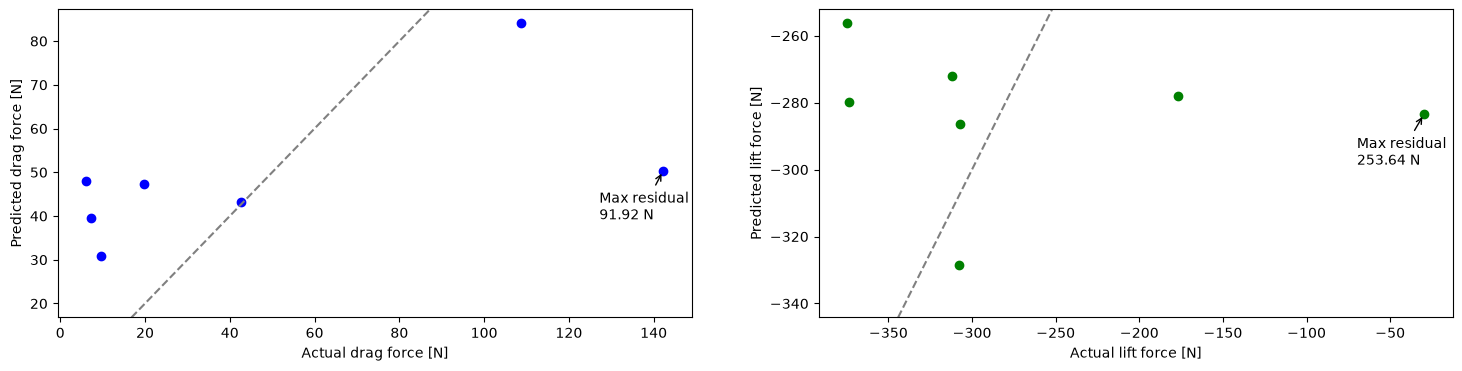

In [620]:
# Plot actual vs predicted for drag and lift, indicating the maximum residuals
fig, axes = plt.subplots(1, 2, figsize=(18, 4))

axes[0].scatter(y_drag, yhat_drag, color='blue')
axes[0].set_xlabel("Actual drag force [N]")
axes[0].set_ylabel("Predicted drag force [N]")
axes[0].axline((20,20), slope=1, linestyle="--", color="grey")
axes[0].annotate(f"Max residual\n{drag_res[drag_max_index]:.2f} N", 
                 xy=(y_drag[drag_max_index], yhat_drag[drag_max_index]), 
                 xytext=(y_drag[drag_max_index]-15, yhat_drag[drag_max_index]-11),
                 arrowprops=dict(arrowstyle="->", color='black'), color='black')


axes[1].scatter(y_lift, yhat_lift, color='green')
axes[1].set_xlabel("Actual lift force [N]")
axes[1].set_ylabel("Predicted lift force [N]")
axes[1].axline((-340,-340), slope=1, linestyle="--", color="grey")
axes[1].annotate(f"Max residual\n{lift_res[lift_max_index]:.2f} N", 
                 xy=(y_lift[lift_max_index], yhat_lift[lift_max_index]), 
                 xytext=(y_lift[lift_max_index]-40, yhat_lift[lift_max_index]-15),
                 arrowprops=dict(arrowstyle="->", color='black'), color='black')
plt.show()

In [621]:
# Fit a GP for drag and lift on the entire dataset
X_data = airfoil_df[["angle_deg"]].to_numpy()
GP_drag = GaussianProcessRegressor(kernel=ConstantKernel() * RBF(), normalize_y = True)
GP_lift = GaussianProcessRegressor(kernel=ConstantKernel() * RBF(), normalize_y = True)
GP_drag.fit(X_data, airfoil_df["drag_N"])
GP_lift.fit(X_data, airfoil_df["lift_N"])

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.",1**2 * RBF(length_scale=1)
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",True
,kernel__k1,1**2
,kernel__k2,RBF(length_scale=1)
,kernel__k1__constant_value,1.0
,kernel__k1__constant_value_bounds,"(1e-05, ...)"
,kernel__k2__length_scale,1.0
,kernel__k2__length_scale_bounds,"(1e-05, ...)"
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-10
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",0


In [622]:
# Report the fitted kernel, the kernel variance, and the length scale for each GP model on the entire dataset
for name, model in [("Drag", GP_drag), ("Lift", GP_lift)]:
    print(name)
    print("Fitted kernel:", model.kernel_)
    print("Kernel variance:", model.kernel_.k1.constant_value)
    print("Length scale:", model.kernel_.k2.length_scale)

Drag
Fitted kernel: 0.991**2 * RBF(length_scale=1.48)
Kernel variance: 0.9822207620467653
Length scale: 1.4808154244217562
Lift
Fitted kernel: 1**2 * RBF(length_scale=0.0656)
Kernel variance: 0.9999986433595162
Length scale: 0.0656492589723371


In [623]:
# Predict the drag and lift values for 100 points within the range of the entire dataset
x_min, x_max = airfoil_df["angle_deg"].min(), airfoil_df["angle_deg"].max()
x_grid = np.linspace(x_min, x_max, 500).reshape(-1, 1)
drag_pred, drag_std = GP_drag.predict(x_grid, return_std=True) 
lift_pred, lift_std = GP_lift.predict(x_grid, return_std=True)
drag_var = drag_std**2
lift_var = lift_std**2

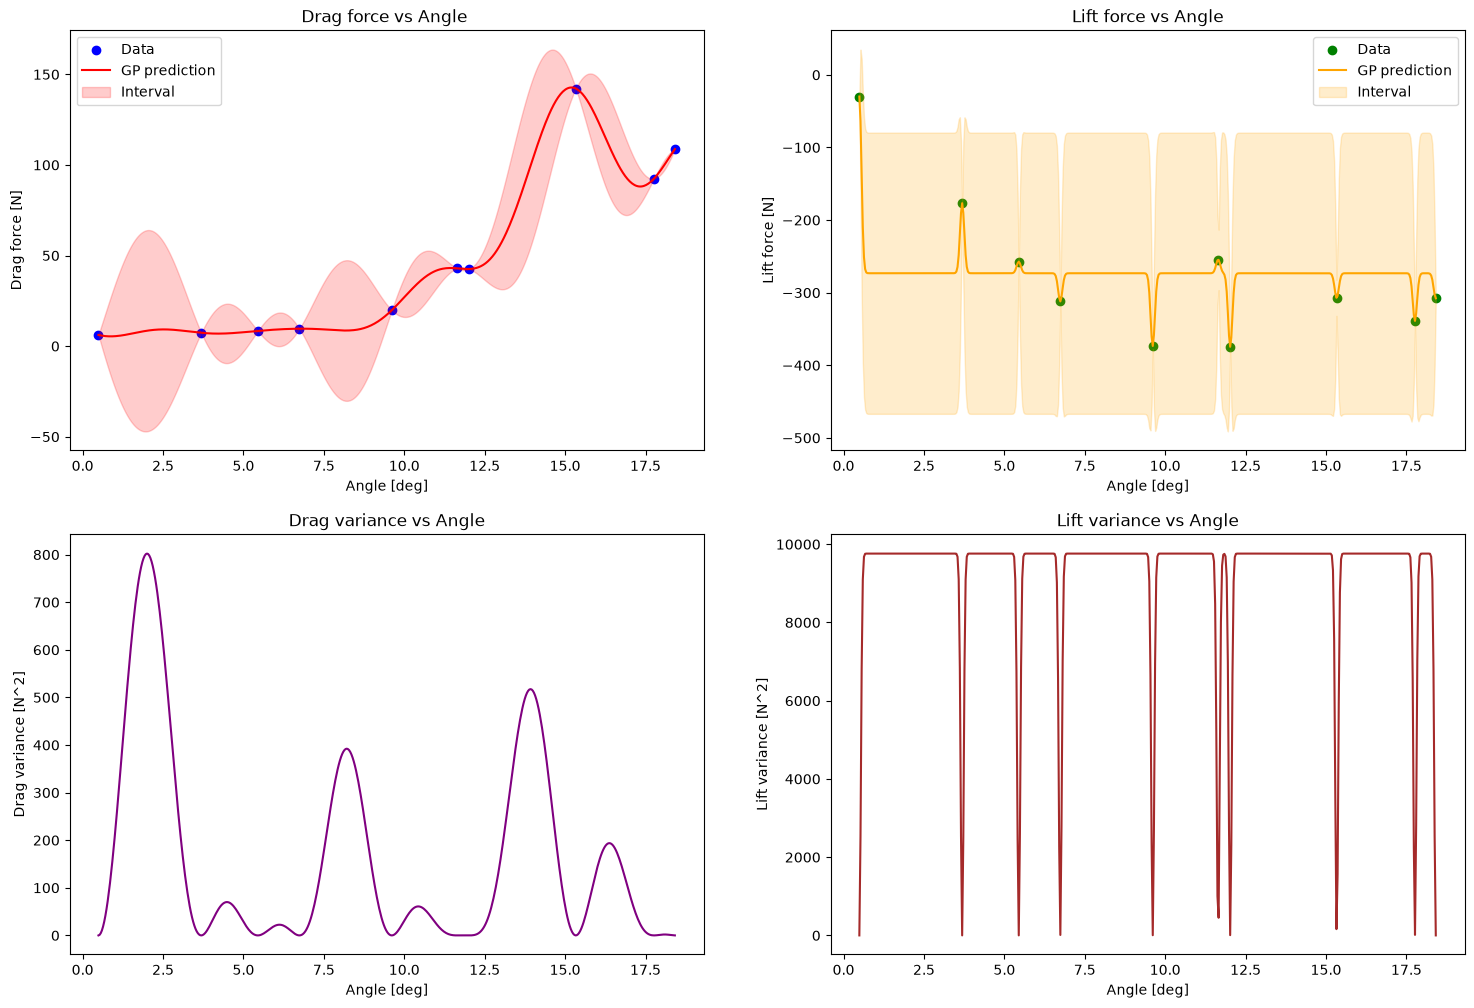

In [624]:
# Plot Drag and Lift vs Angle with confidence intervals, and Drag and Lift variance vs Angle
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

axes[0,0].scatter(airfoil_df["angle_deg"], airfoil_df["drag_N"], color='blue', label='Data')
axes[0,0].plot(x_grid, drag_pred, color='red', label='GP prediction')
axes[0,0].fill_between(x_grid.flatten(), drag_pred - 1.96 * drag_std, drag_pred + 1.96 * drag_std, color='red', alpha=0.2, label='Interval')
axes[0,0].set_xlabel("Angle [deg]")
axes[0,0].set_ylabel("Drag force [N]")
axes[0,0].set_title("Drag force vs Angle ")
axes[0,0].legend()


axes[0,1].scatter(airfoil_df["angle_deg"], airfoil_df["lift_N"], color='green', label='Data')
axes[0,1].plot(x_grid, lift_pred, color='orange', label='GP prediction')
axes[0,1].fill_between(x_grid.flatten(), lift_pred - 1.96 * lift_std, lift_pred + 1.96 * lift_std, color='orange', alpha=0.2, label='Interval')
axes[0,1].set_xlabel("Angle [deg]")
axes[0,1].set_ylabel("Lift force [N]")
axes[0,1].set_title("Lift force vs Angle")
axes[0,1].legend()


axes[1,0].plot(x_grid, drag_var, color='purple')
axes[1,0].set_xlabel("Angle [deg]")   
axes[1,0].set_ylabel("Drag variance [N^2]")
axes[1,0].set_title("Drag variance vs Angle")


axes[1,1].plot(x_grid, lift_var, color='brown')
axes[1,1].set_xlabel("Angle [deg]")
axes[1,1].set_ylabel("Lift variance [N^2]")
axes[1,1].set_title("Lift variance vs Angle")
plt.show()

In [633]:
print("Angle at maximum variance for drag:", x_grid[np.argmax(drag_var)])

Angle at maximum variance for drag: [2.00015377]


From the above plots, the drag force has its highest variance at about 2 deg, while the lift force has a constant high variance value at any angle between the sampled angles. The plotted variance measures the uncertainty of the predicted force obtained from the GP model, which is higher whenever the model has less information around a certain angle.

The mesh size, convergence or turbulence in Ansys Fluent could affect how reliable the computed drag and lift forces are. Computed forces which are inconsistent and with high sensitivity directly impact the lengthscale and kernel variance learned by the GP model, often resulting in a high variance of the mean response between sampled points.

In [625]:
# Compute the drag-to-downforce ratio for the predicted values, as long as the downforce is above the minimum threshold
downforce_pred = -lift_pred
drag_to_downforce_pred = np.where(downforce_pred>=minimum_downforce, drag_pred / downforce_pred, np.nan)

In [626]:
# Report the best response drag-to-downforce ratio and the corresponding angle, drag, and downforce values
best_ratio_index = np.nanargmin(drag_to_downforce_pred)
angle_best_ratio = x_grid[best_ratio_index][0]
drag_best_ratio = drag_pred[best_ratio_index]
downforce_best_ratio = downforce_pred[best_ratio_index]

print("Best drag_to_downforce ratio:", drag_to_downforce_pred.min())
print("Angle at best ratio:", angle_best_ratio)
print("Drag at best ratio:", drag_best_ratio)
print("Downforce at best ratio:", downforce_best_ratio)

Best drag_to_downforce ratio: 0.019758979970126697
Angle at best ratio: 0.850872472775661
Drag at best ratio: 5.398556807681338
Downforce at best ratio: 273.2204200744843


In [627]:
# Report the best sampled drag-to-downforce ratio and the corresponding angle, drag, and downforce values
best_sampled_ratio_index = np.nanargmin(airfoil_df["drag_to_downforce"])
angle_best_sampled_ratio = airfoil_df["angle_deg"].iloc[best_sampled_ratio_index]
drag_best_sampled_ratio = airfoil_df["drag_N"].iloc[best_sampled_ratio_index]
downforce_best_sampled_ratio = -airfoil_df["lift_N"].iloc[best_sampled_ratio_index]

print("Best sampled drag_to_downforce ratio:", airfoil_df["drag_to_downforce"].min())
print("Angle at best sampled ratio:", angle_best_sampled_ratio)
print("Drag at best sampled ratio:", drag_best_sampled_ratio)
print("Downforce at best sampled ratio:", downforce_best_sampled_ratio)

Best sampled drag_to_downforce ratio: 0.030847321370201217
Angle at best sampled ratio: 6.7386990543342975
Drag at best sampled ratio: 9.6258326
Downforce at best sampled ratio: 312.0476


The eligible angle with the best ratio is 0.85 deg, with Drag 5.40 N and Downforce 273.22 N. This angle is very distinct from 6.74 deg, which is the sampled angle with the best ratio. At that sampled angle, the Drag is 9.63 N and Downforce is 312 N.

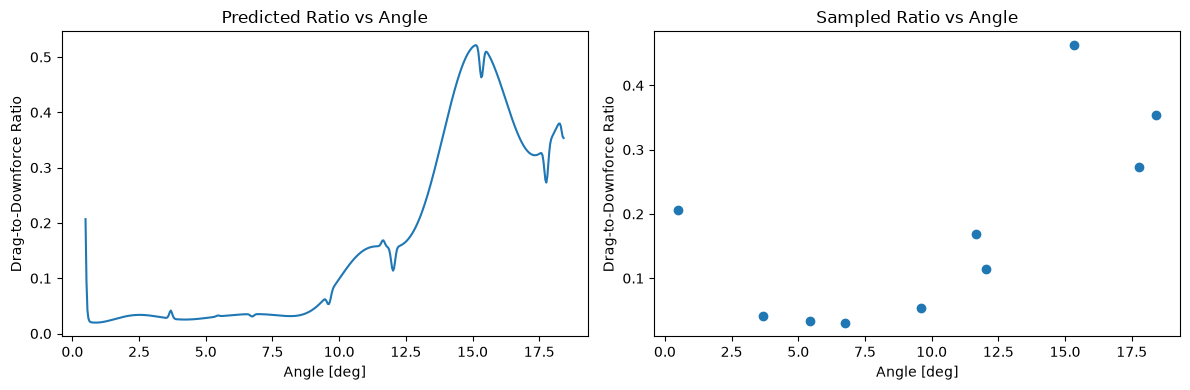

In [637]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(x_grid, drag_to_downforce_pred)
axes[0].set_xlabel("Angle [deg]")
axes[0].set_ylabel("Drag-to-Downforce Ratio")
axes[0].set_title("Predicted Ratio vs Angle")

axes[1].scatter(airfoil_df["angle_deg"], airfoil_df["drag_to_downforce"])
axes[1].set_xlabel("Angle [deg]")
axes[1].set_ylabel("Drag-to-Downforce Ratio")
axes[1].set_title("Sampled Ratio vs Angle")

plt.tight_layout()
plt.show()

The GP predicts the lowest ratio near the eligible angle of 0.87 deg. However, lift variance is high around this angle, and it is close to the sampled angle of 0.49 deg, which also had the largest absolute lift prediction error. With only ten CFD runs, the model does not provide enough evidence to identify a final best angle yet.

We recommend a follow-up simulation at 1.5 deg to gather information around the unexplored sampled region between 0.49 deg and 3.69 deg. This region lies within the broader range from 0.49 deg to 6.74 deg, where the sampled ratios show a decreasing trend. The GP also predicts relatively low ratios in this range. The new run would help test whether the trend continues and clarify the force predictions near the eligible angle with the lowest predicted ratio.

A small ratio alone is unreliable to conclude about the total downforce of the car. Different drag and downforce combinations can yield the same ratio, e.g., 1/3 and 2/6.

After running the additional Fluent simulation at 1.5 deg, we will compare its drag and lift with the GPs predicted mean values and compare the observed ratio  with the predicted ratio. This should help assess how accurate the current model was at the recommended angle. After that, we will add the new result to the dataset, refit both GPs, and use the updated predictions and variances to guide new simulation runs.

One limitation is that a 2D section model cannot capture airflow around the wing tips of race car wing.